###    Fase 3 - Camanda Gold, perguntas de negócio e gráficos    ###

Após limpeza e tipagem na camada SILVER, criaremos a camada GOLD (tabela e views) e responderemos as 7 perguntas de negócio. Cada pergunta seguirá o caminho: pergunta → consulta SQL → tabela → gráfico → conclusão

## BIBLIOTECAS E CONEXÃO ##

In [1]:
import warnings
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from banco import conectar

# Ignora o aviso do Pandas sobre SQLAlchemy
warnings.filterwarnings("ignore", message="pandas only supports SQLAlchemy")

# Mostra os números com 2 casas decimais
pd.set_option("display.float_format", "{:.2f}".format)


conexao = conectar()

def consultar(sql):
    return pd.read_sql(sql, conexao)


def formatar_numero(valor, casas=2):
    texto = f"{valor:,.{casas}f}"
    return texto.replace(",", "X").replace(".", ",").replace("X", ".")


# Teste de validação
teste = consultar("SELECT COUNT(*) AS viagens FROM silver_viagem")
print("Conexão OK. Viagens na camada Silver:", teste["viagens"][0])

Conexão OK. Viagens na camada Silver: 341860


### Bloco 1: As 3 Primeiras Perguntas (Camada Silver) ###

Pergunta 1: Os 5 órgãos com maior custo total?

,orgao_superior,gasto_total_formatado
0,Ministério da Justiça e Segurança Pública,"R$ 488.831.110,61"
1,Ministério da Defesa,"R$ 156.549.767,91"
2,Ministério da Educação,"R$ 111.897.434,35"
3,Ministério do Meio Ambiente e Mudança do Clima,"R$ 50.123.043,80"
4,Ministério da Previdência Social,"R$ 40.659.494,63"


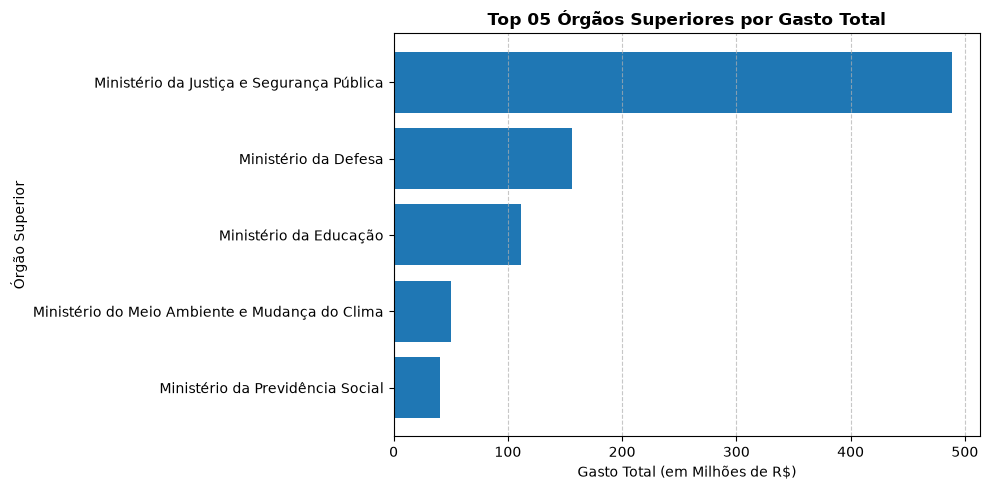

In [5]:
##Identifica quais ministérios ou órgãos concentram a maior parte das despesas com diárias e passagens.

# 1. Consulta SQL
sql_p1 = """
SELECT 
    v.nome_orgao_superior AS orgao_superior,
    ROUND(SUM(p.valor), 2) AS gasto_total
FROM silver_viagem v
JOIN silver_pagamento p ON v.id_viagem = p.id_viagem
GROUP BY v.nome_orgao_superior
ORDER BY gasto_total DESC
LIMIT 5;
"""

# 2. Execução e exibição da Tabela
df_p1 = consultar(sql_p1)

# Formatação visual para o relatório
df_p1_formatado = df_p1.copy()
df_p1_formatado["gasto_total_formatado"] = df_p1_formatado["gasto_total"].apply(
    lambda x: f"R$ {formatar_numero(x)}"
)
display(df_p1_formatado[["orgao_superior", "gasto_total_formatado"]])

# 3. Gráfico de Barras Horizontais
plt.figure(figsize=(10, 5))
plt.barh(df_p1["orgao_superior"][::-1], df_p1["gasto_total"][::-1] / 1e6, color="#1f77b4")
plt.title("Top 05 Órgãos Superiores por Gasto Total", fontsize=12, weight="bold")
plt.xlabel("Gasto Total (em Milhões de R$)")
plt.ylabel("Órgão Superior")
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

Pergunta 2: Os 3 destinos com maior custo médio por viagem?

,destino_principal,total_viagens,custo_medio
0,Nova Maringá/MT,5,70621.26
1,Cologne/Alemanha,12,50847.25
2,Planalto/RS,17,47156.89


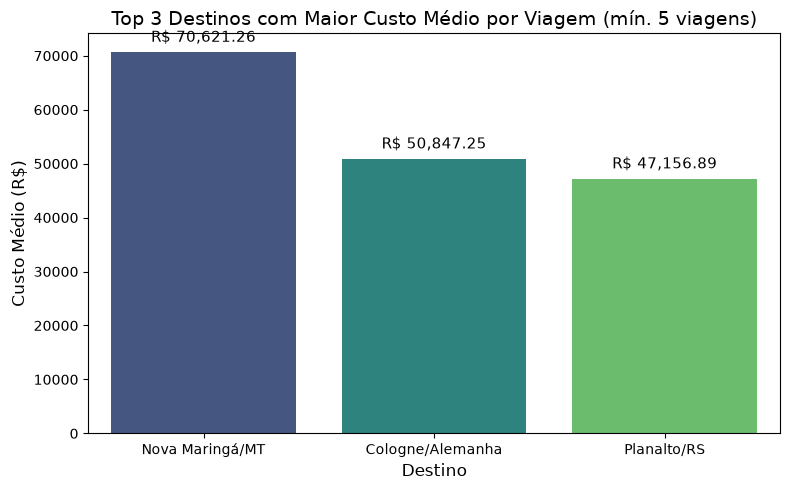

In [12]:
# --- Pergunta 2: Top 3 destinos com maior custo médio por viagem ---
query_p2 = """
SELECT 
    TRIM(SPLIT_PART(destinos, ',', 1)) AS destino_principal,
    COUNT(id_viagem) AS total_viagens,
    ROUND(AVG(valor_total), 2) AS custo_medio
FROM silver_viagem
WHERE destinos IS NOT NULL AND destinos != ''
GROUP BY destino_principal
HAVING COUNT(id_viagem) >= 5
ORDER BY custo_medio DESC
LIMIT 3;
"""

df_p2 = consultar(query_p2)

# Exibe a tabela diretamente sem depender de jinja2
display(df_p2)

# Gráfico de Colunas sem aviso de depreciação
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=df_p2, 
    x="destino_principal", 
    y="custo_medio", 
    hue="destino_principal", 
    palette="viridis", 
    legend=False
)
plt.title("Top 3 Destinos com Maior Custo Médio por Viagem (mín. 5 viagens)", fontsize=14)
plt.xlabel("Destino", fontsize=12)
plt.ylabel("Custo Médio (R$)", fontsize=12)

# Rótulo de valores sobre as colunas
for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f"R$ {height:,.2f}",
        (p.get_x() + p.get_width() / 2.0, height),
        va="bottom",
        ha="center",
        xytext=(0, 5),
        textcoords="offset points",
        fontsize=11
    )

plt.tight_layout()
plt.show()

Pergunta 3: A viagem de maior duração e seu custo total?

,id_viagem,nome_viajante,cargo,nome_orgao_superior,data_inicio,data_fim,duracao_dias,valor_total
0,0000000000020699856,LUISANGELA CORREA FRANCO DE FARIA,TECNICO DO SEGURO SOCIAL,Ministério da Previdência Social,2025-01-13,2026-01-31,384,0.00


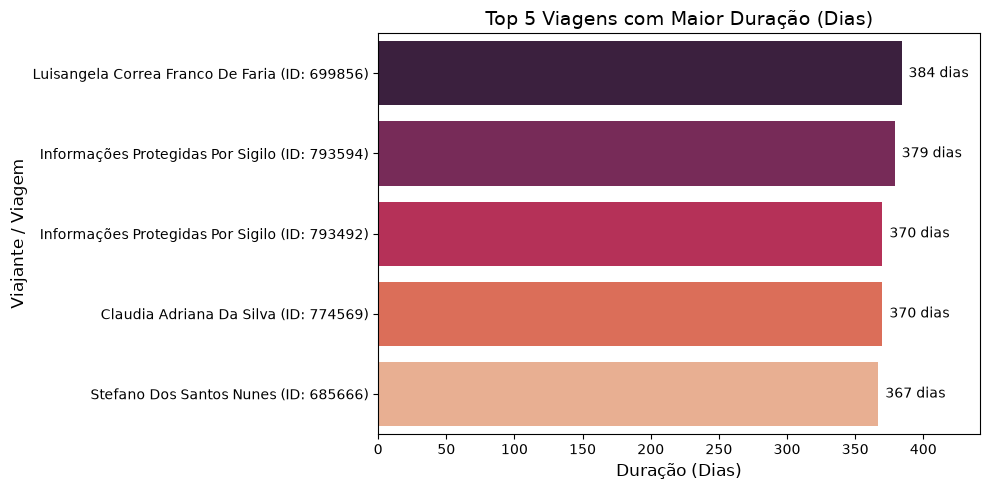

In [13]:

query_p3 = """
SELECT 
    id_viagem,
    nome_viajante,
    cargo,
    nome_orgao_superior,
    data_inicio,
    data_fim,
    duracao_dias,
    valor_total
FROM silver_viagem
WHERE duracao_dias IS NOT NULL
ORDER BY duracao_dias DESC, valor_total DESC
LIMIT 1;
"""

df_p3 = consultar(query_p3)
display(df_p3)

# Comparativo: Top 5 viagens de maior duração para visualização gráfica
query_p3_comp = """
SELECT 
    id_viagem,
    nome_viajante,
    nome_orgao_superior,
    duracao_dias,
    valor_total
FROM silver_viagem
WHERE duracao_dias IS NOT NULL
ORDER BY duracao_dias DESC
LIMIT 5;
"""

df_p3_comp = consultar(query_p3_comp)

# Cria um rótulo limpo combinando o nome do viajante com o ID abreviado
df_p3_comp["rotulo_viagem"] = df_p3_comp["nome_viajante"].str.title() + " (ID: " + df_p3_comp["id_viagem"].str[-6:] + ")"

# Gráfico de Barras Horizontais para não encavalar os textos
plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=df_p3_comp,
    x="duracao_dias",
    y="rotulo_viagem",
    hue="rotulo_viagem",
    palette="rocket",
    legend=False
)

plt.title("Top 5 Viagens com Maior Duração (Dias)", fontsize=14)
plt.xlabel("Duração (Dias)", fontsize=12)
plt.ylabel("Viajante / Viagem", fontsize=12)

# Adiciona a anotação dos dias na ponta de cada barra
for p in ax.patches:
    width = p.get_width()
    ax.annotate(
        f"{int(width)} dias",
        (width, p.get_y() + p.get_height() / 2.0),
        va="center",
        ha="left",
        xytext=(5, 0),
        textcoords="offset points",
        fontsize=10
    )

# Dá uma margem no eixo X para o texto não encostar na borda
plt.xlim(0, df_p3_comp["duracao_dias"].max() * 1.15)
plt.tight_layout()
plt.show()

### Criação da Camada Gold: VIEW e TABELA Agregadas (JOIN + GROUP BY) ###

Depois de concluir as 3 primeiras análises na camada Silver, criamos a camada Gold agregando os dados de pagamentos e viagens:

In [2]:
# --- Modelagem da Camada Gold (VIEW e TABELA agregadas) ---
from banco import conectar

# Garante que a conexão exista
try:
    conexao
except NameError:
    conexao = conectar()

cur = conexao.cursor()

# 1. VIEW Gold agregada por órgão pagador e tipo de pagamento
sql_view_gold = """
CREATE OR REPLACE VIEW vw_gold_pagamentos_orgao AS
SELECT 
    p.nome_orgao_pagador,
    p.tipo_pagamento,
    COUNT(DISTINCT p.id_viagem) AS qtd_viagens_atendidas,
    COUNT(p.id_pagamento) AS total_lancamentos,
    ROUND(SUM(p.valor), 2) AS valor_total_pago,
    ROUND(AVG(p.valor), 2) AS valor_medio_pago
FROM silver_pagamento p
GROUP BY p.nome_orgao_pagador, p.tipo_pagamento;
"""
cur.execute(sql_view_gold)

# 2. Materialização física da Camada Gold como Tabela
sql_tabela_gold = """
DROP TABLE IF EXISTS gold_pagamentos_orgao CASCADE;
CREATE TABLE gold_pagamentos_orgao AS
SELECT * FROM vw_gold_pagamentos_orgao;
"""
cur.execute(sql_tabela_gold)

conexao.commit()
cur.close()

print("✓ Camada Gold criada com sucesso: VIEW 'vw_gold_pagamentos_orgao' e TABELA 'gold_pagamentos_orgao'!")

✓ Camada Gold criada com sucesso: VIEW 'vw_gold_pagamentos_orgao' e TABELA 'gold_pagamentos_orgao'!


Pergunta 4: Qual o tipo de pagamento com maior valor médio?

,tipo_pagamento,media_valor
0,PASSAGEM,1795.91
1,DIÁRIAS,1522.52
2,Serviço correlato: seguro,523.21
3,RESTITUIÇÃO,420.31


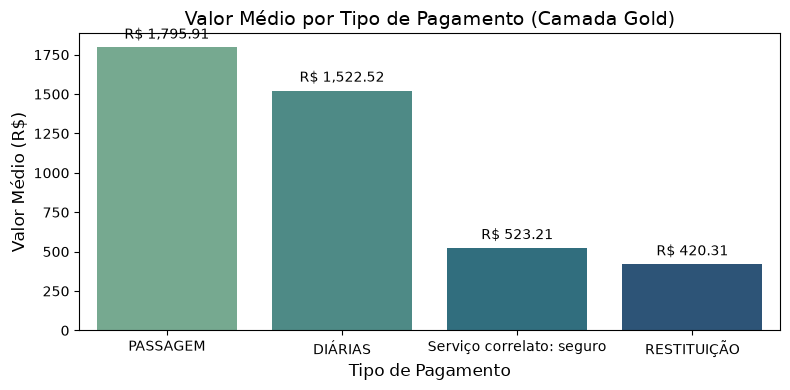

In [17]:
query_p4 = """
SELECT 
    tipo_pagamento,
    ROUND(AVG(valor_medio_pago), 2) AS media_valor
FROM gold_pagamentos_orgao
GROUP BY tipo_pagamento
ORDER BY media_valor DESC;
"""

df_p4 = consultar(query_p4)
display(df_p4)

plt.figure(figsize=(8, 4))
ax = sns.barplot(
    data=df_p4, 
    x="tipo_pagamento", 
    y="media_valor", 
    hue="tipo_pagamento", 
    palette="crest", 
    legend=False
)
plt.title("Valor Médio por Tipo de Pagamento (Camada Gold)", fontsize=14)
plt.xlabel("Tipo de Pagamento", fontsize=12)
plt.ylabel("Valor Médio (R$)", fontsize=12)

for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f"R$ {height:,.2f}",
        (p.get_x() + p.get_width() / 2.0, height),
        va="bottom",
        ha="center",
        xytext=(0, 4),
        textcoords="offset points",
        fontsize=10
    )

plt.tight_layout()
plt.show()

In [8]:
import pandas as pd
from banco import conectar

try:
    conexao
except NameError:
    conexao = conectar()

def consultar(sql):
    return pd.read_sql(sql, conexao)

Pergunta 5: Qual o meio de transporte mais usado nos trechos?

,meio_transporte,total_trechos
0,Brasília,79962
1,Rio de Janeiro,36403
2,São Paulo,27222
3,Manaus,14214
4,Recife,13731
5,Curitiba,12509
6,Belo Horizonte,12136
7,Boa Vista,11670
8,Porto Alegre,11642
9,Guarulhos,11119


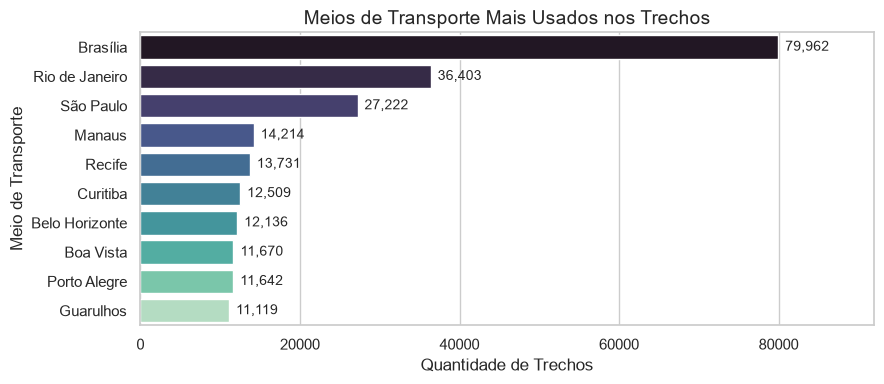

In [9]:
# --- Pergunta 5: Meio de transporte mais usado nos trechos ---
query_p5 = """
SELECT 
    meio_transporte,
    COUNT(*) AS total_trechos
FROM silver_trecho
WHERE meio_transporte IS NOT NULL 
  AND TRIM(meio_transporte) != ''
GROUP BY meio_transporte
ORDER BY total_trechos DESC
LIMIT 10;
"""

df_p5 = consultar(query_p5)
display(df_p5)

# Gráfico de barras horizontais com renderização limpa
plt.figure(figsize=(9, 4))
ax = sns.barplot(
    data=df_p5, 
    x="total_trechos", 
    y="meio_transporte", 
    hue="meio_transporte", 
    palette="mako", 
    legend=False
)

plt.title("Meios de Transporte Mais Usados nos Trechos", fontsize=14)
plt.xlabel("Quantidade de Trechos", fontsize=12)
plt.ylabel("Meio de Transporte", fontsize=12)

# Adiciona anotações nas pontas das barras
for p in ax.patches:
    width = p.get_width()
    if width > 0:
        ax.annotate(
            f"{int(width):,}",
            (width, p.get_y() + p.get_height() / 2.0),
            va="center",
            ha="left",
            xytext=(5, 0),
            textcoords="offset points",
            fontsize=10
        )

# Margem para o texto não encostar na borda direita
plt.xlim(0, df_p5["total_trechos"].max() * 1.15)
plt.tight_layout()
plt.show()

Pergunta 6: Qual UF de destino aparece em mais trechos?

,destino_uf,total_trechos
0,Brasil,748578
1,Estados Unidos da América,2049
2,França,1213
3,Portugal,990
4,China,665
5,Espanha,630
6,Itália,627
7,Alemanha,610
8,Argentina,606
9,Suíça,422


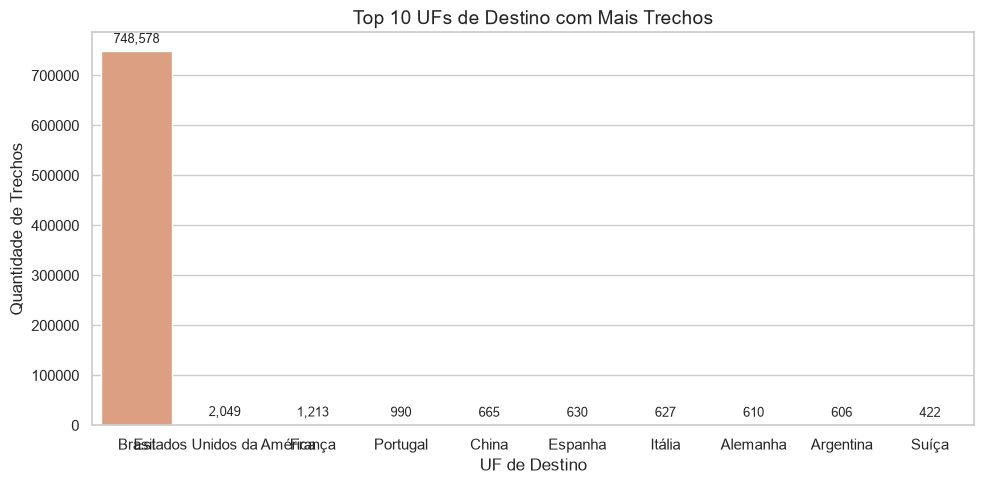

In [6]:
# --- Pergunta 6: UF de destino que mais aparece nos trechos ---
query_p6 = """
SELECT 
    destino_uf,
    COUNT(*) AS total_trechos
FROM silver_trecho
WHERE destino_uf IS NOT NULL AND destino_uf != ''
GROUP BY destino_uf
ORDER BY total_trechos DESC
LIMIT 10;
"""

df_p6 = consultar(query_p6)
display(df_p6)

plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=df_p6, 
    x="destino_uf", 
    y="total_trechos", 
    hue="destino_uf", 
    palette="flare", 
    legend=False
)
plt.title("Top 10 UFs de Destino com Mais Trechos", fontsize=14)
plt.xlabel("UF de Destino", fontsize=12)
plt.ylabel("Quantidade de Trechos", fontsize=12)

for p in ax.patches:
    height = p.get_height()
    ax.annotate(
        f"{int(height):,}",
        (p.get_x() + p.get_width() / 2.0, height),
        va="bottom",
        ha="center",
        xytext=(0, 4),
        textcoords="offset points",
        fontsize=9
    )

plt.tight_layout()
plt.show()

Pergunta 7: Qual órgão pagou mais no total?

,nome_orgao_pagador,total_pago
0,Fundo Nacional de Segurança Pública,2.784810e+08
1,Sigiloso,2.004848e+08
2,Comando da Aeronáutica,8.176914e+07
3,Instituto Nacional do Seguro Social,3.742760e+07
4,Comando do Exército,3.687264e+07


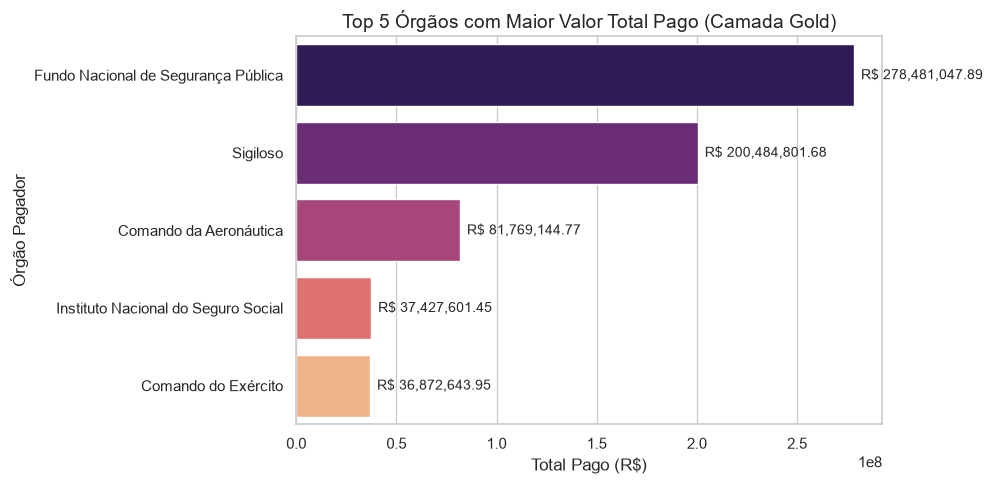

In [7]:
# --- Pergunta 7: Órgão com maior valor total pago (Camada Gold) ---
query_p7 = """
SELECT 
    nome_orgao_pagador,
    ROUND(SUM(valor_total_pago), 2) AS total_pago
FROM gold_pagamentos_orgao
WHERE nome_orgao_pagador IS NOT NULL
GROUP BY nome_orgao_pagador
ORDER BY total_pago DESC
LIMIT 5;
"""

df_p7 = consultar(query_p7)
display(df_p7)

plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=df_p7, 
    x="total_pago", 
    y="nome_orgao_pagador", 
    hue="nome_orgao_pagador", 
    palette="magma", 
    legend=False
)
plt.title("Top 5 Órgãos com Maior Valor Total Pago (Camada Gold)", fontsize=14)
plt.xlabel("Total Pago (R$)", fontsize=12)
plt.ylabel("Órgão Pagador", fontsize=12)

for p in ax.patches:
    width = p.get_width()
    ax.annotate(
        f"R$ {width:,.2f}",
        (width, p.get_y() + p.get_height() / 2.0),
        va="center",
        ha="left",
        xytext=(5, 0),
        textcoords="offset points",
        fontsize=10
    )

plt.tight_layout()
plt.show()

In [10]:
conexao.close()
print("✓ Todas as análises concluídas e conexão com o banco fechada com segurança!")

✓ Todas as análises concluídas e conexão com o banco fechada com segurança!
